In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Every figure is also saved to figures/ so it can be reused in the report and slides
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)


def save_fig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

# Load the cleaned purchases saved by 01_preprocessing_eda.ipynb
DATA_DIR = Path("data")
cleaned_df = pd.read_pickle(DATA_DIR / "cleaned_df.pkl")

## Customer-level RFM features

- Recency: days since the customer's last purchase, counted from the day after the last invoice in the data
- Frequency: number of different invoices
- Monetary: total spending in GBP

In [2]:
# Build customer-level RFM features for segmentation
snapshot_date = cleaned_df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm_df = cleaned_df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda d: (snapshot_date - d.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalPrice", "sum"),
).reset_index()

print("RFM shape:", rfm_df.shape)
rfm_df.describe()

RFM shape: (4338, 4)


,CustomerID,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000,4338.000000
mean,15300.408022,92.536422,4.272015,2054.266460
std,1721.808492,100.014169,7.697998,8989.230441
min,12346.000000,1.000000,1.000000,3.750000
25%,13813.250000,18.000000,1.000000,307.415000
50%,15299.500000,51.000000,2.000000,674.485000
75%,16778.750000,142.000000,5.000000,1661.740000
max,18287.000000,374.000000,209.000000,280206.020000


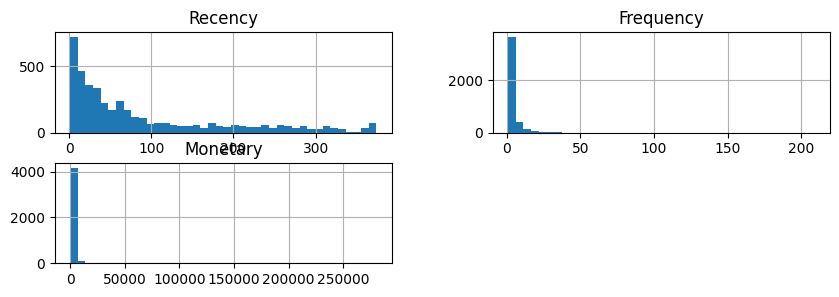

,Raw,Log
Recency,1.25,-0.38
Frequency,12.07,1.21
Monetary,19.32,0.39


In [3]:
# Check skew, then log-transform and standardize for clustering
from sklearn.preprocessing import StandardScaler

rfm_features = ["Recency", "Frequency", "Monetary"]

rfm_df[rfm_features].hist(bins=40, figsize=(10, 3))
save_fig("rfm_raw_histograms")
plt.show()

rfm_log = np.log1p(rfm_df[rfm_features])
rfm_scaled = pd.DataFrame(
    StandardScaler().fit_transform(rfm_log),
    columns=rfm_features,
)

# Skewness before and after the log transform (0 means symmetric)
pd.DataFrame({"Raw": rfm_df[rfm_features].skew(), "Log": rfm_log.skew()}).round(2)

Frequency and Monetary are very skewed (skewness about 12 and 19), so a few huge customers would pull the cluster centers toward them. Taking `log1p` brings that down to about 1.2 and 0.4. We then standardize so all three features count equally in the distance calculation, since K-means uses Euclidean distance.

## Choosing the number of clusters (K)

K-means needs the number of clusters before it runs. We fit K-means on the scaled log-RFM features for K = 2 to 10 and compare two measures:

- **Inertia** (within-cluster sum of squared distances) always falls as K grows. We look for the *elbow*, where adding clusters stops giving large improvements.
- **Silhouette score** (from -1 to 1) measures how much closer each customer is to its own cluster than to the nearest other cluster. Higher is better.

In [4]:
# Fit K-means for K = 2..10 and record inertia, silhouette score, and smallest cluster size
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_values = range(2, 11)
k_results = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = kmeans.fit_predict(rfm_scaled)
    k_results.append({
        "K": k,
        "Inertia": kmeans.inertia_,
        "Silhouette": silhouette_score(rfm_scaled, labels),
        "SmallestCluster": np.bincount(labels).min(),
    })

k_results_df = pd.DataFrame(k_results).set_index("K")

# Percent reduction in inertia compared with the previous K
k_results_df["InertiaDropPct"] = -k_results_df["Inertia"].pct_change() * 100
k_results_df.round(3)

,Inertia,Silhouette,SmallestCluster,InertiaDropPct
K,,,,
2,6481.225,0.433,1667,NaN
3,4867.847,0.337,770,24.893
4,3938.510,0.337,716,19.091
5,3295.976,0.316,343,16.314
6,2855.011,0.313,328,13.379
7,2548.914,0.310,223,10.721
8,2336.778,0.301,216,8.323
9,2155.648,0.282,211,7.751
10,1999.903,0.279,93,7.225


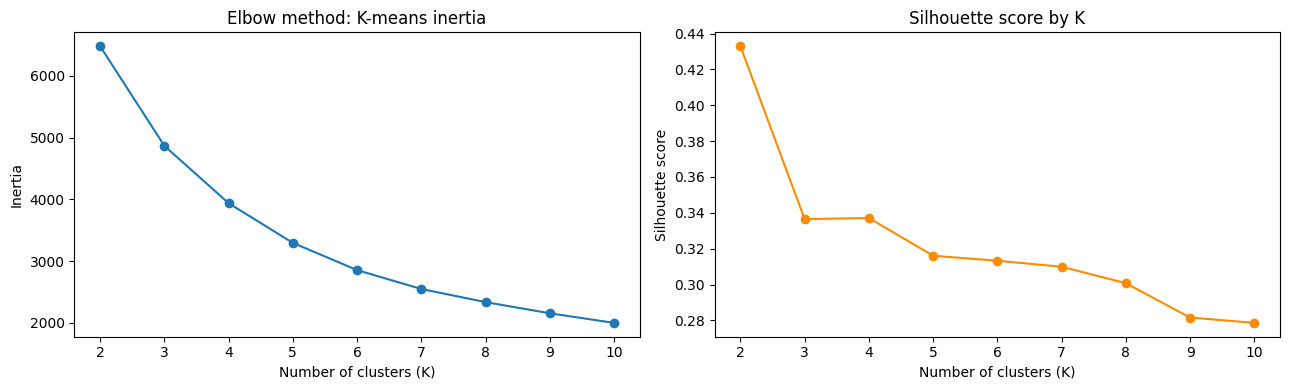

In [5]:
# Plot the elbow curve and silhouette scores side by side
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(k_results_df.index, k_results_df["Inertia"], marker="o")
axes[0].set(title="Elbow method: K-means inertia", xlabel="Number of clusters (K)", ylabel="Inertia")

axes[1].plot(k_results_df.index, k_results_df["Silhouette"], marker="o", color="darkorange")
axes[1].set(title="Silhouette score by K", xlabel="Number of clusters (K)", ylabel="Silhouette score")

for ax in axes:
    ax.set_xticks(list(k_values))

plt.tight_layout()
save_fig("elbow_silhouette")
plt.show()

### Selected K = 4

- **K = 2 has the highest silhouette (0.433)**, but two clusters only separate recent, frequent buyers from lapsed ones. That is too coarse for targeted marketing.
- **Elbow:** inertia drops by about 25% from K = 2 to 3 and 19% from 3 to 4, then each extra cluster removes less (16%, 13%, 11%, ...). The bend is around K = 3 to 4.
- **Silhouette at K = 3 and K = 4 is essentially tied (0.337)** and declines steadily after K = 4.
- K = 4 gives one more segment than K = 3 at no real cost in separation, and every cluster still has 700+ customers, so no segment is too small to act on.
- **Limitation:** silhouette scores around 0.34 mean the segments overlap moderately. Customer RFM behaviour is closer to a continuum than to sharply separated groups.

In [6]:
# Number of clusters used for the final K-means model and agglomerative comparison
chosen_k = 4
k_results_df.loc[[chosen_k]].round(3)

,Inertia,Silhouette,SmallestCluster,InertiaDropPct
K,,,,
4,3938.51,0.337,716,19.091


## Final K-means model

We train K-means with the selected K = 4 on the scaled log-RFM features and assign a cluster label to each customer.

In [7]:
# Train the final K-means model with the selected number of clusters
final_kmeans = KMeans(n_clusters=chosen_k, n_init=10, random_state=42)
kmeans_labels = final_kmeans.fit_predict(rfm_scaled)

print("Inertia:", round(final_kmeans.inertia_, 3))
print("Silhouette score:", round(silhouette_score(rfm_scaled, kmeans_labels), 3))

Inertia: 3938.51
Silhouette score: 0.337


In [8]:
# Assign each customer its K-means cluster label
rfm_df["KMeansCluster"] = kmeans_labels
rfm_df.head()

,CustomerID,Recency,Frequency,Monetary,KMeansCluster
0,12346.0,326,1,77183.60,2
1,12347.0,2,7,4310.00,1
2,12348.0,75,4,1797.24,2
3,12349.0,19,1,1757.55,0
4,12350.0,310,1,334.40,3


### Stability check

K-means starts from random centers, so we refit it with ten different seeds and compare each result with the final model using the Adjusted Rand Index (1 = same clusters, 0 = no better than chance).

In [9]:
# Refit K-means with different random seeds and compare each result with the final model
from sklearn.metrics import adjusted_rand_score

seed_ari = pd.Series(
    {
        seed: adjusted_rand_score(
            kmeans_labels,
            KMeans(n_clusters=chosen_k, n_init=10, random_state=seed).fit_predict(rfm_scaled),
        )
        for seed in range(10)
    },
    name="ARI vs final model",
)
seed_ari.index.name = "Seed"

print(f"ARI across 10 seeds: min {seed_ari.min():.3f}, mean {seed_ari.mean():.3f}, max {seed_ari.max():.3f}")
seed_ari.round(3).to_frame().T

ARI across 10 seeds: min 0.942, mean 0.973, max 0.989


Seed,0,1,2,3,4,5,6,7,8,9
ARI vs final model,0.985,0.963,0.969,0.966,0.987,0.969,0.989,0.984,0.942,0.976


The ARI is between 0.94 and 0.99 for every seed, so the clusters don't depend on the random start.

## Analyze and visualize K-means clusters

For the fitted K-means model we report:

- **Cluster sizes:** how many customers fall in each segment
- **Median RFM statistics:** typical recency, frequency, and monetary value in each cluster
- **2D PCA plot:** scaled RFM features projected to two dimensions

In [10]:
# Cluster sizes and share of customers
kmeans_sizes = (
    rfm_df["KMeansCluster"]
    .value_counts()
    .sort_index()
    .rename("Customers")
    .to_frame()
)
kmeans_sizes["SharePct"] = kmeans_sizes["Customers"] / kmeans_sizes["Customers"].sum() * 100
kmeans_sizes.round(1)

,Customers,SharePct
KMeansCluster,,
0,837,19.3
1,716,16.5
2,1173,27.0
3,1612,37.2


In [11]:
# Median RFM statistics on the original (unscaled) features
kmeans_medians = (
    rfm_df.groupby("KMeansCluster")[["Recency", "Frequency", "Monetary"]]
    .median()
    .round(2)
)
kmeans_medians

,Recency,Frequency,Monetary
KMeansCluster,,,
0,17.0,2.0,471.70
1,8.0,10.0,3733.87
2,56.0,4.0,1345.62
3,177.0,1.0,298.26


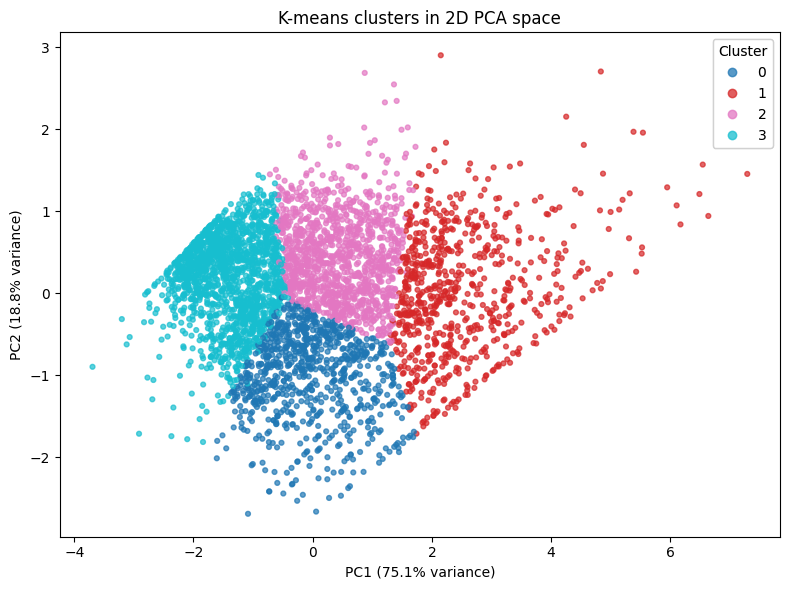

Variance explained by 2 PCs: 0.939


,Recency,Frequency,Monetary
PC1,-0.512,0.618,0.597
PC2,0.850,0.262,0.457


In [12]:
# 2D PCA of scaled RFM features, colored by K-means cluster
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
rfm_pca = pca.fit_transform(rfm_scaled)

fig, ax = plt.subplots(figsize=(8, 6))
scatter = ax.scatter(
    rfm_pca[:, 0],
    rfm_pca[:, 1],
    c=rfm_df["KMeansCluster"],
    cmap="tab10",
    s=12,
    alpha=0.7,
)
ax.set(
    title="K-means clusters in 2D PCA space",
    xlabel=f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)",
    ylabel=f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)",
)
legend = ax.legend(*scatter.legend_elements(), title="Cluster")
ax.add_artist(legend)
plt.tight_layout()
save_fig("kmeans_pca")
plt.show()

print("Variance explained by 2 PCs:", pca.explained_variance_ratio_.sum().round(3))

# Loadings: how much each scaled RFM feature contributes to each principal component
pca_loadings = pd.DataFrame(pca.components_, columns=rfm_scaled.columns, index=["PC1", "PC2"])
pca_loadings.round(3)

The first two components keep about 94% of the variance, so the 2D plot is a good picture of the data. PC1 goes up with Frequency and Monetary and down with Recency, so customers further right are more valuable. PC2 is mostly Recency. The clusters sit next to each other along PC1 without clear gaps, which fits the moderate silhouette score.

In [13]:
# Save the results needed by the next notebooks (03_agglomerative_comparison.ipynb and 04_segments_recommendations.ipynb)
pd.to_pickle(rfm_df, DATA_DIR / "rfm_df.pkl")
pd.to_pickle(rfm_scaled, DATA_DIR / "rfm_scaled.pkl")
pd.to_pickle(rfm_pca, DATA_DIR / "rfm_pca.pkl")
pd.to_pickle(kmeans_sizes, DATA_DIR / "kmeans_sizes.pkl")
pd.to_pickle(kmeans_medians, DATA_DIR / "kmeans_medians.pkl")
pd.to_pickle(chosen_k, DATA_DIR / "chosen_k.pkl")